
# PR2 — Detección de intrusiones con Random Forest

**Estudiante:** _Apellidos, Nombre_  
**Fecha:** _2026-11-30_  
**Dataset:** `data/PR2_IDS_Mini.csv`

> Esta plantilla contiene **estructura, TODOs y pistas**.



## Objetivos
- Preparar datos de IDS (limpieza + EDA + preprocesado).
- Entrenar un **RandomForestClassifier** baseline y otro optimizado.
- Evaluar con **accuracy, precision, recall, F1**, y **matriz de confusión**.
- Registrar iteraciones de búsqueda y justificar la configuración final.


In [31]:

# === Rutas de proyecto ===
from pathlib import Path
BASE = Path().resolve()
DATA = BASE / "data" / "PR2_IDS_Mini.csv"
OUT_DIR = BASE / "resultados"
FIG_DIR = OUT_DIR / "figuras"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
print("BASE:", BASE)
print("DATA:", DATA)


BASE: /content
DATA: /content/data/PR2_IDS_Mini.csv


In [32]:

# === Importaciones ===
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import matplotlib.pyplot as plt

# NOTA: Si haces gráficos, usa una figura por gráfico y no fijes estilos/colores.



---
## A) Carga y EDA básica

**Tareas:**
- Cargar CSV en `df` (revisar `info()`, nulos, tipos).
- Distribución de `is_attack` y `attack_family` (desbalanceo).
- Identificar columnas categóricas vs numéricas y valores atípicos.

**Pistas:** `df.isna().sum()`, `df.describe()`, `df['attack_family'].value_counts(normalize=True)`.


In [33]:
print("=== A1. Estructura del DataFrame ===")
print("Dimensiones (filas, columnas):", df.shape)   # shape = (filas, columnas)
df.info()                                           # columnas, nº de no nulos y tipo de cada una

=== A1. Estructura del DataFrame ===
Dimensiones (filas, columnas): (8000, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   flow_id         8000 non-null   int64  
 1   timestamp       8000 non-null   object 
 2   protocol_type   8000 non-null   object 
 3   service         8000 non-null   object 
 4   flag            8000 non-null   object 
 5   duration        8000 non-null   float64
 6   src_bytes       8000 non-null   int64  
 7   dst_bytes       8000 non-null   int64  
 8   pkts            8000 non-null   int64  
 9   bytes_ratio     7928 non-null   float64
 10  login_attempts  7929 non-null   float64
 11  failed_logins   8000 non-null   int64  
 12  count_60s       8000 non-null   int64  
 13  srv_count_60s   8000 non-null   int64  
 14  same_srv_rate   8000 non-null   float64
 15  serror_rate     8000 non-null   float64
 16 

In [34]:
print("=== A2. Nulos por columna ===")
# isna() marca con True cada celda vacía; sum() cuenta cuántas hay en cada columna
print(df.isna().sum())

=== A2. Nulos por columna ===
flow_id            0
timestamp          0
protocol_type      0
service            0
flag               0
duration           0
src_bytes          0
dst_bytes          0
pkts               0
bytes_ratio       72
login_attempts    71
failed_logins      0
count_60s          0
srv_count_60s      0
same_srv_rate      0
serror_rate        0
rerror_rate        0
is_attack          0
attack_family      0
dtype: int64


In [35]:
print("=== A3. Balance de clases ===")
# value_counts() cuenta filas por valor; con normalize=True da la proporción (0.55 = 55 %)
print("is_attack (nº de flujos):")
print(df['is_attack'].value_counts())
print("\nis_attack (proporción):")
print(df['is_attack'].value_counts(normalize=True))
print("\nattack_family (nº de flujos):")
print(df['attack_family'].value_counts())
print("\nattack_family (proporción):")
print(df['attack_family'].value_counts(normalize=True))

=== A3. Balance de clases ===
is_attack (nº de flujos):
is_attack
0    4400
1    3600
Name: count, dtype: int64

is_attack (proporción):
is_attack
0    0.55
1    0.45
Name: proportion, dtype: float64

attack_family (nº de flujos):
attack_family
normal        4400
dos           1200
portscan       960
bruteforce     800
webattack      640
Name: count, dtype: int64

attack_family (proporción):
attack_family
normal        0.55
dos           0.15
portscan      0.12
bruteforce    0.10
webattack     0.08
Name: proportion, dtype: float64


In [36]:
print("=== A4. Variables categóricas ===")
# Para cada columna de texto, cuántos flujos hay de cada valor
for c in ['protocol_type', 'service', 'flag']:
    print(f"\n--- {c} ---")        # f"..." mete el nombre de la columna dentro del texto
    print(df[c].value_counts())

=== A4. Variables categóricas ===

--- protocol_type ---
protocol_type
tcp     6393
udp     1322
icmp     285
Name: count, dtype: int64

--- service ---
service
http      2103
https     1474
dns       1096
ssh        946
smtp       478
ftp        377
ntp        353
pop3       288
imap       276
rdp        258
snmp       178
telnet     173
Name: count, dtype: int64

--- flag ---
flag
SF      4984
S0      1366
REJ      854
RSTO     361
RSTR     280
SH       155
Name: count, dtype: int64


In [37]:
print("=== A5. Resumen estadístico (describe) ===")
# display() pinta la tabla bien formateada en Colab (en vez del texto cortado en trozos)
# .T la gira: una fila por variable, más fácil de leer
display(df.describe().T)

print("=== A5. Percentiles de las variables de volumen ===")
cols = ['duration', 'src_bytes', 'dst_bytes', 'pkts', 'bytes_ratio']
# quantile() da el valor por debajo del cual queda ese % de los datos (0.99 = percentil 99)
display(df[cols].quantile([0, .25, .5, .75, .95, .99, 1]).T)

=== A5. Resumen estadístico (describe) ===


,count,mean,std,min,25%,50%,75%,max
flow_id,8000.0,4000.500000,2309.545410,1.000000,2000.750000,4000.500000,6000.250000,8000.000000
duration,8000.0,3.405872,4.277531,0.106460,1.075732,2.030450,4.058018,71.306320
src_bytes,8000.0,17082.972000,18388.699164,71.000000,5840.750000,11554.500000,21963.250000,300000.000000
dst_bytes,8000.0,15910.556875,24836.083874,6.000000,1711.250000,8000.000000,20112.250000,400000.000000
pkts,8000.0,42.575000,57.372753,2.000000,13.000000,26.000000,50.000000,1101.000000
bytes_ratio,7928.0,10.591894,31.386631,0.007326,0.546662,1.664333,6.743407,587.931562
login_attempts,7929.0,0.703872,1.950662,0.000000,0.000000,0.000000,0.000000,15.000000
failed_logins,8000.0,0.592250,1.873280,0.000000,0.000000,0.000000,0.000000,15.000000
count_60s,8000.0,14.243125,20.242140,0.000000,3.000000,6.000000,20.000000,337.000000
srv_count_60s,8000.0,10.637625,17.060911,0.000000,1.000000,4.000000,14.000000,258.000000


=== A5. Percentiles de las variables de volumen ===


,0.00,0.25,0.50,0.75,0.95,0.99,1.00
duration,0.106460,1.075732,2.030450,4.058018,10.731072,20.576276,71.306320
src_bytes,71.000000,5840.750000,11554.500000,21963.250000,50156.200000,89804.900000,300000.000000
dst_bytes,6.000000,1711.250000,8000.000000,20112.250000,56620.050000,119801.390000,400000.000000
pkts,2.000000,13.000000,26.000000,50.000000,130.000000,299.000000,1101.000000
bytes_ratio,0.007326,0.546662,1.664333,6.743407,49.709265,149.030248,587.931562


=== A6 y A7. Histogramas de las variables de volumen ===


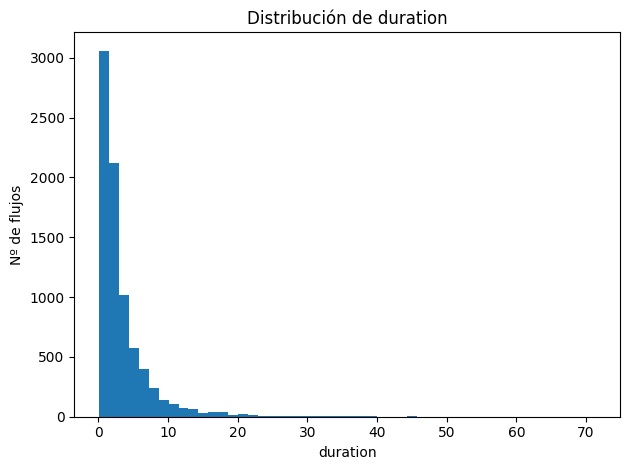

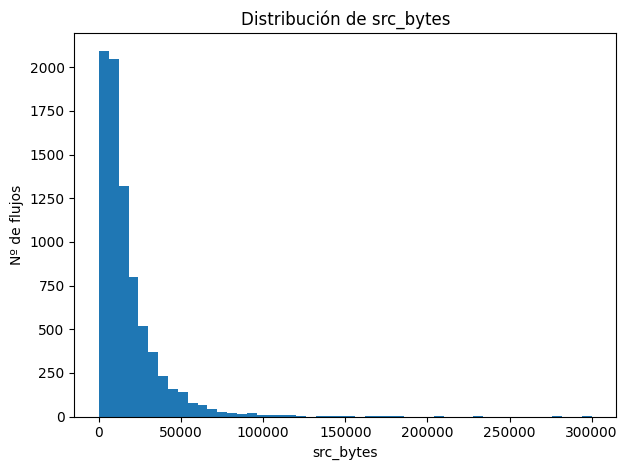

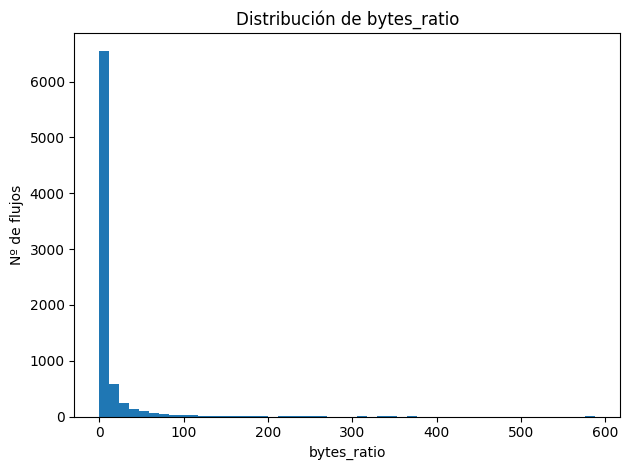

In [38]:
print("=== A6 y A7. Histogramas de las variables de volumen ===")

# Histograma: reparte los flujos en 50 tramos (bins) de valores y cuenta cuántos caen en cada uno.
# Si casi todo está a la izquierda y hay una cola larga a la derecha, hay valores extremos.
# dropna() quita los nulos, porque el gráfico no puede dibujarlos.
for c in ['duration', 'src_bytes', 'bytes_ratio']:
    plt.figure()                              # una figura nueva por variable (lo pide la plantilla)
    plt.hist(df[c].dropna(), bins=50)         # dibuja el histograma con 50 tramos
    plt.title(f"Distribución de {c}")         # título con el nombre de la columna
    plt.xlabel(c)                             # etiqueta del eje X: la variable
    plt.ylabel("Nº de flujos")                # etiqueta del eje Y: cuántos flujos hay en cada tramo
    plt.tight_layout()                        # ajusta márgenes para que no se corte nada
    plt.show()                                # muestra la figura

In [39]:
print("=== A8. Comprobación del README ===")
# nulos de failed_logins (el README decía que había)
print("Nulos en failed_logins:", df['failed_logins'].isna().sum())
# valores distintos de flag (el README mencionaba OTH)
print("Valores de flag:", df['flag'].unique())

=== A8. Comprobación del README ===
Nulos en failed_logins: 0
Valores de flag: ['S0' 'SF' 'RSTR' 'REJ' 'RSTO' 'SH']



---
## B) Selección de variables y preprocesado

**Objetivo:** dejar listas las matrices `X` (features) y `y` (label binaria `is_attack`).  
No incluyas en `X`: `flow_id`, `timestamp`, `is_attack`, `attack_family`.

**Tareas:**
- Definir listas `cat_features` y `num_features`.
- Pipeline con `ColumnTransformer`: `OneHotEncoder(handle_unknown='ignore')` en categóricas y *passthrough* en numéricas.
- Imputación simple de nulos (por ejemplo con `SimpleImputer`) si lo consideras necesario.

**Pistas:** Puedes añadir `SimpleImputer` antes del modelo o dentro de un sub-pipeline para numéricas.


In [40]:
from sklearn.impute import SimpleImputer   # rellena los valores que faltan

print("=== B1. Variables de entrada (X) y objetivo (y) ===")

target = 'is_attack'                                         # lo que queremos predecir
drop_cols = ['flow_id', 'timestamp', 'attack_family', target]  # columnas que NO entran en X

X = df.drop(columns=drop_cols)    # drop quita esas columnas y deja el resto como entrada
y = df[target]                    # y es solo la columna is_attack (0 = normal, 1 = ataque)

cat_features = ['protocol_type', 'service', 'flag']                        # las de texto
num_features = [c for c in X.columns if c not in cat_features]            # el resto son numéricas

print("X:", X.shape, "| y:", y.shape)
print(f"Categóricas ({len(cat_features)}):", cat_features)
print(f"Numéricas ({len(num_features)}):", num_features)

=== B1. Variables de entrada (X) y objetivo (y) ===
X: (8000, 15) | y: (8000,)
Categóricas (3): ['protocol_type', 'service', 'flag']
Numéricas (12): ['duration', 'src_bytes', 'dst_bytes', 'pkts', 'bytes_ratio', 'login_attempts', 'failed_logins', 'count_60s', 'srv_count_60s', 'same_srv_rate', 'serror_rate', 'rerror_rate']


In [41]:
# ColumnTransformer: cada tupla es (nombre, transformación, columnas a las que se aplica)
preprocessor = ColumnTransformer([
    # OneHotEncoder: convierte cada valor de texto en columnas de 0 y 1.
    # handle_unknown='ignore': si en test aparece un valor que no se vio al entrenar,
    # pone todo a 0 en vez de dar error.
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
    # SimpleImputer(median): sustituye cada nulo por la mediana de esa columna
    ('num', SimpleImputer(strategy='median'), num_features),
])

# Al dejarlo como última línea de la celda, Colab dibuja un diagrama del preprocesador
preprocessor

ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['protocol_type', 'service', 'flag']),
                                ('num', SimpleImputer(strategy='median'),
                                 ['duration', 'src_bytes', 'dst_bytes', 'pkts',
                                  'bytes_ratio', 'login_attempts',
                                  'failed_logins', 'count_60s', 'srv_count_60s',
                                  'same_srv_rate', 'serror_rate',
                                  'rerror_rate'])])

In [42]:
print("=== B3. División entrenamiento / test (80/20, estratificada) ===")

# test_size=0.2 -> 20 % para test; stratify=y -> mantiene la proporción de clases;
# random_state=SEED -> semilla fija, así sale siempre la misma división
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nProporción de is_attack en cada conjunto:")
print("Total:", y.mean().round(4))        # mean() de una columna 0/1 = proporción de unos
print("Train:", y_train.mean().round(4))
print("Test: ", y_test.mean().round(4))

# Los nulos siguen aquí: se imputarán dentro del pipeline, no antes
print("\nNulos en X_train:")
print(X_train[['bytes_ratio', 'login_attempts']].isna().sum())

=== B3. División entrenamiento / test (80/20, estratificada) ===
Train: (6400, 15) | Test: (1600, 15)

Proporción de is_attack en cada conjunto:
Total: 0.45
Train: 0.45
Test:  0.45

Nulos en X_train:
bytes_ratio       61
login_attempts    55
dtype: int64


In [43]:
print("=== B4. Comprobación del preprocesado (solo con train) ===")

# fit_transform: aprende (medianas, categorías) con X_train y lo aplica
Xt = preprocessor.fit_transform(X_train)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt   # si saliera en formato "disperso", lo pasamos a normal

print("Forma tras el preprocesado:", Xt.shape)          # nº de filas y columnas resultantes
print("Nulos que quedan:", np.isnan(Xt).sum())           # debería ser 0
print("Primeras columnas:", list(preprocessor.get_feature_names_out()[:8]))

=== B4. Comprobación del preprocesado (solo con train) ===
Forma tras el preprocesado: (6400, 33)
Nulos que quedan: 0
Primeras columnas: ['cat__protocol_type_icmp', 'cat__protocol_type_tcp', 'cat__protocol_type_udp', 'cat__service_dns', 'cat__service_ftp', 'cat__service_http', 'cat__service_https', 'cat__service_imap']



---
## C) Modelo baseline (RandomForestClassifier por defecto)

**Tareas:**
- Construir un `Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(random_state=SEED))])`.
- Ajustar con el *train*.
- Evaluar en *test*: accuracy, precision, recall, F1, matriz de confusión, reporte de clasificación.
- Guardar la matriz de confusión como figura en `resultados/figuras/`.

**Pistas:** revisa `classification_report()` por clase. Si quieres, añade **ROC-AUC** binario.


In [44]:
print("=== C1. Entrenamiento del baseline ===")

# Pipeline: lista de pasos que se ejecutan en orden.
#   'prep' -> el preprocesador de la Etapa B (One-Hot + mediana)
#   'clf'  -> el Random Forest, con sus ajustes por defecto (solo fijamos la semilla)
pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(random_state=SEED)),
])

# fit = entrenar. El pipeline ajusta el preprocesado y el modelo SOLO con los datos de train
pipe.fit(X_train, y_train)

# predict = usar el modelo ya entrenado sobre datos que no ha visto (test).
# Devuelve un 0 o un 1 por cada flujo
y_pred = pipe.predict(X_test)

# Guardamos los ajustes por defecto del RF para poder compararlos con el modelo optimizado
params = pipe.named_steps['clf'].get_params()
for p in ['n_estimators', 'max_depth', 'min_samples_split', 'min_samples_leaf', 'max_features']:
    print(p, "=", params[p])

=== C1. Entrenamiento del baseline ===
n_estimators = 100
max_depth = None
min_samples_split = 2
min_samples_leaf = 1
max_features = sqrt


In [45]:
print("=== C2. Métricas del baseline (sobre test) ===")

# Cada función compara las respuestas reales (y_test) con las predichas (y_pred).
# zero_division=0 evita un error si alguna métrica dividiera entre cero.
acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec  = recall_score(y_test, y_pred, zero_division=0)
f1   = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1       : {f1:.4f}")

# Guardamos las cifras en un diccionario para la tabla comparativa de la Etapa D
metrics_baseline = {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

=== C2. Métricas del baseline (sobre test) ===
Accuracy : 0.9925
Precision: 0.9944
Recall   : 0.9889
F1       : 0.9916


=== C3. Matriz de confusión del baseline ===
Normales bien clasificados (TN): 876
Falsas alarmas, normal marcado como ataque (FP): 4
Ataques no detectados (FN): 8
Ataques detectados (TP): 712


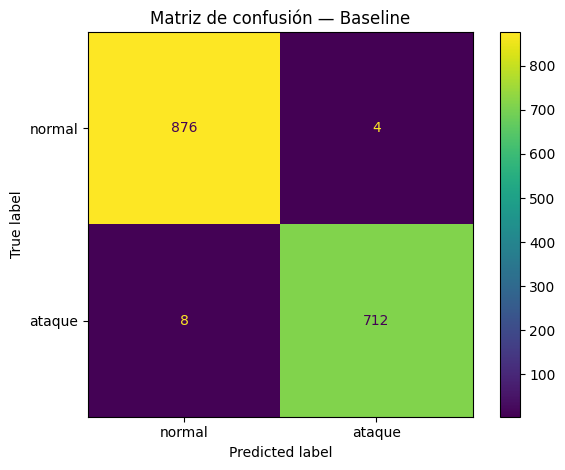

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay   # dibuja la matriz con los números dentro

print("=== C3. Matriz de confusión del baseline ===")

# confusion_matrix devuelve una tabla 2x2: filas = realidad, columnas = predicción
cm = confusion_matrix(y_test, y_pred)

# ravel() la aplana en este orden: TN, FP, FN, TP
tn, fp, fn, tp = cm.ravel()
print(f"Normales bien clasificados (TN): {tn}")
print(f"Falsas alarmas, normal marcado como ataque (FP): {fp}")
print(f"Ataques no detectados (FN): {fn}")
print(f"Ataques detectados (TP): {tp}")

# Dibujamos la matriz con etiquetas legibles
disp = ConfusionMatrixDisplay(cm, display_labels=['normal', 'ataque'])
disp.plot()
plt.title("Matriz de confusión — Baseline")
plt.tight_layout()

# Guardamos con el nombre EXACTO que pide el enunciado, antes de mostrarla
plt.savefig(FIG_DIR / "confusion_matrix_baseline.png", dpi=120)
plt.show()

In [47]:
print("=== C4. Informe de clasificación del baseline ===")

# Da precision, recall y F1 por separado para cada clase (0 = normal, 1 = ataque)
print(classification_report(y_test, y_pred, target_names=['normal', 'ataque']))

=== C4. Informe de clasificación del baseline ===
              precision    recall  f1-score   support

      normal       0.99      1.00      0.99       880
      ataque       0.99      0.99      0.99       720

    accuracy                           0.99      1600
   macro avg       0.99      0.99      0.99      1600
weighted avg       0.99      0.99      0.99      1600




---
## D) Búsqueda de hiperparámetros (GridSearchCV o RandomizedSearchCV)

**Tareas:**
- Definir espacio de búsqueda (ej.):  
  - `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`.
- Usar `StratifiedKFold` con semilla y `n_splits=5` (o 3 si tu equipo es limitado).  
- Guardar `cv_results_` a `resultados/cv_results.csv`.  
- Reentrenar el mejor modelo y evaluar en *test* (mismas métricas que baseline).

**Pistas:** Para `max_features`, considera `sqrt`, `log2` o un float ∈ (0,1].


In [48]:
print("=== D1. Configuración de la búsqueda ===")

# Cada lista son los valores que probará. El prefijo 'clf__' significa
# "este ajuste es del paso 'clf' (el Random Forest) del pipeline".
param_grid = {
    'clf__n_estimators':      [100, 200],        # nº de árboles
    'clf__max_depth':         [None, 10, 20],    # profundidad máxima (None = sin límite)
    'clf__min_samples_split': [2, 5],            # mínimo de muestras para dividir un nodo
    'clf__min_samples_leaf':  [1, 2],            # mínimo de muestras en cada hoja
    'clf__max_features':      ['sqrt', 0.3, 0.5],# nº de variables que mira cada división
}

# StratifiedKFold: 5 trozos que mantienen la proporción de ataques; shuffle mezcla antes
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# GridSearchCV: pipeline a probar, combinaciones, validación cruzada,
# métrica para elegir (f1), n_jobs=-1 usa todos los núcleos, verbose=1 muestra el progreso
search = GridSearchCV(pipe, param_grid=param_grid, cv=cv,
                      scoring='f1', n_jobs=-1, verbose=1)

# Multiplicamos el nº de valores de cada lista para contar las combinaciones
n_comb = 1
for valores in param_grid.values():
    n_comb *= len(valores)
print("Combinaciones:", n_comb, "| entrenamientos totales (x5 pliegues):", n_comb * 5)

=== D1. Configuración de la búsqueda ===
Combinaciones: 72 | entrenamientos totales (x5 pliegues): 360


In [49]:
print("=== D2. Ejecución de la búsqueda ===")

# Tarda unos minutos. Prueba todas las combinaciones, solo con los datos de train
search.fit(X_train, y_train)

# cv_results_ guarda el resultado de cada combinación, lo pasamos a tabla y lo guardamos
cv_df = pd.DataFrame(search.cv_results_)
cv_df.to_csv(OUT_DIR / "cv_results.csv", index=False)   # archivo que pide el enunciado

print("Mejores hiperparámetros:", search.best_params_)
print("Mejor F1 en validación cruzada:", round(search.best_score_, 4))

=== D2. Ejecución de la búsqueda ===
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Mejores hiperparámetros: {'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__min_samples_split': 2, 'clf__n_estimators': 200}
Mejor F1 en validación cruzada: 0.9936


In [50]:
print("=== D3. Las 10 mejores combinaciones ===")

cols = ['rank_test_score', 'mean_test_score', 'std_test_score',
        'param_clf__n_estimators', 'param_clf__max_depth',
        'param_clf__min_samples_split', 'param_clf__min_samples_leaf',
        'param_clf__max_features']
# mean_test_score = F1 medio de los 5 pliegues, std = cuánto varía entre pliegues
display(cv_df.sort_values('rank_test_score')[cols].head(10).round(4))

=== D3. Las 10 mejores combinaciones ===


,rank_test_score,mean_test_score,std_test_score,param_clf__n_estimators,param_clf__max_depth,param_clf__min_samples_split,param_clf__min_samples_leaf,param_clf__max_features
1,1,0.9936,0.0018,200,None,2,1,sqrt
51,2,0.9936,0.0021,200,20,5,1,sqrt
3,3,0.9936,0.0021,200,None,5,1,sqrt
49,4,0.9934,0.0020,200,20,2,1,sqrt
5,5,0.9932,0.0010,200,None,2,2,sqrt
53,5,0.9932,0.0010,200,20,2,2,sqrt
55,7,0.9932,0.0013,200,20,5,2,sqrt
0,8,0.9932,0.0021,100,None,2,1,sqrt
48,8,0.9932,0.0021,100,20,2,1,sqrt
31,10,0.9932,0.0017,200,10,5,2,sqrt


In [51]:
print("=== D4. F1 medio en CV según el valor de cada hiperparámetro ===")

# Para cada hiperparámetro, agrupamos las combinaciones por su valor y miramos
# el F1 medio y el máximo. Si un valor cambia poco el resultado, el parámetro influye poco.
# astype(str) evita que max_depth=None desaparezca de la tabla.
param_cols = [c for c in cv_df.columns if c.startswith('param_')]
for p in param_cols:
    tabla = cv_df.groupby(cv_df[p].astype(str))['mean_test_score'].agg(['mean', 'max']).round(4)
    print("\n" + p)
    print(tabla)

=== D4. F1 medio en CV según el valor de cada hiperparámetro ===

param_clf__max_depth
                        mean     max
param_clf__max_depth                
10                    0.9920  0.9932
20                    0.9922  0.9936
None                  0.9922  0.9936

param_clf__max_features
                           mean     max
param_clf__max_features                
0.3                      0.9920  0.9925
0.5                      0.9914  0.9922
sqrt                     0.9930  0.9936

param_clf__min_samples_leaf
                               mean     max
param_clf__min_samples_leaf                
1                            0.9922  0.9936
2                            0.9920  0.9932

param_clf__min_samples_split
                                mean     max
param_clf__min_samples_split                
2                             0.9922  0.9936
5                             0.9921  0.9936

param_clf__n_estimators
                           mean     max
param_clf__n_estimators

In [52]:
from sklearn.model_selection import cross_val_score   # nota media de un modelo con CV

print("=== D5. F1 en validación cruzada: baseline frente a mejor modelo ===")

# Mismo CV que la búsqueda, para comparar en igualdad de condiciones
scores_base = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1)
print(f"Baseline : {scores_base.mean():.4f} (± {scores_base.std():.4f})")

i = search.best_index_    # posición de la mejor combinación en cv_df
print(f"Mejor    : {cv_df.loc[i, 'mean_test_score']:.4f} (± {cv_df.loc[i, 'std_test_score']:.4f})")

=== D5. F1 en validación cruzada: baseline frente a mejor modelo ===
Baseline : 0.9932 (± 0.0021)
Mejor    : 0.9936 (± 0.0018)


In [53]:
print("=== D6. Mejor modelo evaluado en test ===")

# best_estimator_ ya viene reentrenado con todo el train (GridSearchCV lo hace por defecto)
best_model = search.best_estimator_
y_pred_best = best_model.predict(X_test)

metrics_best = {
    'accuracy':  accuracy_score(y_test, y_pred_best),
    'precision': precision_score(y_test, y_pred_best, zero_division=0),
    'recall':    recall_score(y_test, y_pred_best, zero_division=0),
    'f1':        f1_score(y_test, y_pred_best, zero_division=0),
}

# Tabla comparativa con el baseline (metrics_baseline viene de la celda C2)
comparativa = pd.DataFrame({'baseline': metrics_baseline, 'optimizado': metrics_best})
comparativa['diferencia'] = comparativa['optimizado'] - comparativa['baseline']
display(comparativa.round(4))

print(classification_report(y_test, y_pred_best, target_names=['normal', 'ataque']))

=== D6. Mejor modelo evaluado en test ===


,baseline,optimizado,diferencia
accuracy,0.9925,0.9925,0.0
precision,0.9944,0.9944,0.0
recall,0.9889,0.9889,0.0
f1,0.9916,0.9916,0.0


              precision    recall  f1-score   support

      normal       0.99      1.00      0.99       880
      ataque       0.99      0.99      0.99       720

    accuracy                           0.99      1600
   macro avg       0.99      0.99      0.99      1600
weighted avg       0.99      0.99      0.99      1600



=== D7. Matriz de confusión del modelo optimizado ===
TN: 876 | FP (falsas alarmas): 4 | FN (ataques no detectados): 8 | TP: 712


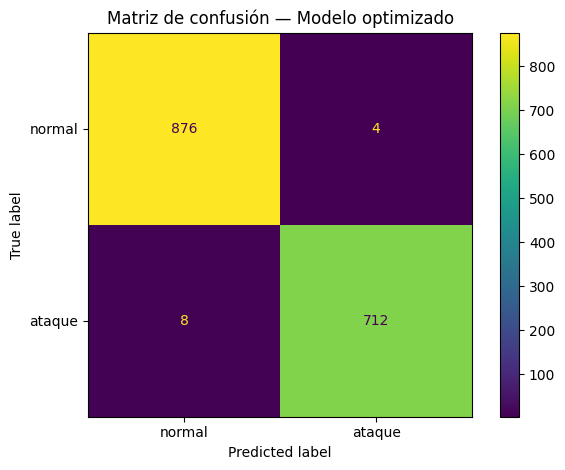

In [54]:
print("=== D7. Matriz de confusión del modelo optimizado ===")

cm_best = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm_best.ravel()
print(f"TN: {tn} | FP (falsas alarmas): {fp} | FN (ataques no detectados): {fn} | TP: {tp}")

disp = ConfusionMatrixDisplay(cm_best, display_labels=['normal', 'ataque'])
disp.plot()
plt.title("Matriz de confusión — Modelo optimizado")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_best.png", dpi=120)   # nombre exacto del enunciado
plt.show()


---
## E) Importancia de características y discusión de overfitting

**Tareas:**
- Extrae importancias del `RandomForest` (ojo: están en el espacio transformado).
- Alternativa: `permutation_importance` sobre el pipeline para obtener importancias globales.
- Compara métricas de CV vs test para detectar sobreajuste.
- Escribe en el informe una **justificación** de tu configuración final (trade-offs).

**Pistas:** si usas `permutation_importance`, limita el número de features para plotear.


In [55]:
from sklearn.inspection import permutation_importance   # importancia por permutación

print("=== E1. Importancia de las variables (permutation importance) ===")

# Para cada columna de X_test: la baraja n_repeats veces, vuelve a predecir con el
# mejor modelo y mide cuánto baja el F1. Más caída = más importante.
# Se aplica al pipeline entero, así que trabaja con las 15 columnas originales.
result = permutation_importance(best_model, X_test, y_test, scoring='f1',
                                n_repeats=10, random_state=SEED, n_jobs=-1)

importancias = pd.DataFrame({
    'variable': X_test.columns,
    'caida_media_f1': result.importances_mean,   # caída media del F1 al barajarla
    'desv': result.importances_std,              # cuánto varía entre las 10 repeticiones
}).sort_values('caida_media_f1', ascending=False)

display(importancias.round(4))

=== E1. Importancia de las variables (permutation importance) ===


,variable,caida_media_f1,desv
11,srv_count_60s,0.1635,0.0064
10,count_60s,0.1465,0.0059
14,rerror_rate,0.0107,0.0025
9,failed_logins,0.0102,0.0012
5,dst_bytes,0.0094,0.0025
12,same_srv_rate,0.0071,0.0021
8,login_attempts,0.0059,0.0010
13,serror_rate,0.0034,0.0018
0,protocol_type,0.0011,0.0009
1,service,0.0002,0.0005


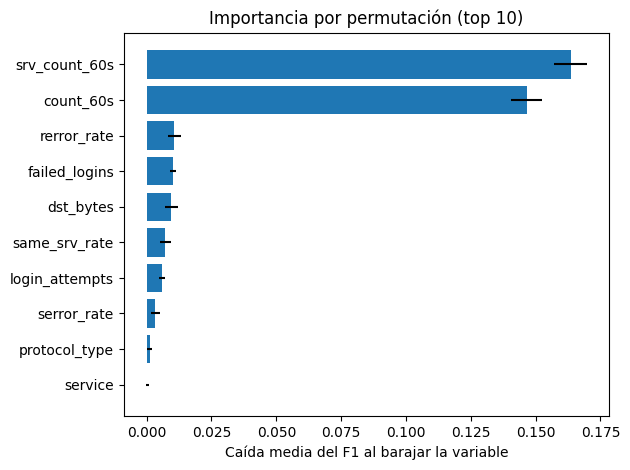

In [56]:
# Gráfico de barras con las 10 variables más importantes
top = importancias.head(10).iloc[::-1]    # iloc[::-1] invierte el orden: la mayor queda arriba
plt.figure()
plt.barh(top['variable'], top['caida_media_f1'], xerr=top['desv'])   # xerr = barra de variación
plt.title("Importancia por permutación (top 10)")
plt.xlabel("Caída media del F1 al barajar la variable")
plt.tight_layout()
plt.savefig(FIG_DIR / "importancias_permutacion.png", dpi=120)
plt.show()

In [57]:
print("=== E3. F1 del mejor modelo: entrenamiento, validación cruzada y test ===")

# F1 sobre los mismos datos con los que se entrenó (no es una nota fiable por sí sola)
f1_train = f1_score(y_train, best_model.predict(X_train))
f1_cv = search.best_score_        # F1 medio en la validación cruzada
f1_test = metrics_best['f1']      # F1 en test (viene de la celda D6)

print(f"Train: {f1_train:.4f}")
print(f"CV   : {f1_cv:.4f}")
print(f"Test : {f1_test:.4f}")
print(f"\nDiferencia CV - test   : {f1_cv - f1_test:.4f}")
print(f"Diferencia train - test: {f1_train - f1_test:.4f}")

=== E3. F1 del mejor modelo: entrenamiento, validación cruzada y test ===
Train: 1.0000
CV   : 0.9936
Test : 0.9916

Diferencia CV - test   : 0.0019
Diferencia train - test: 0.0084



---
## F) Checklist de entrega

- [ ] Notebook ejecutable sin errores (tras completar los TODOs).
- [ ] `resultados/cv_results.csv` con el registro de búsqueda.
- [ ] Métricas baseline y optimizadas (comparadas en el informe).
- [ ] Matrices de confusión guardadas en `resultados/figuras/`.
- [ ] Justificación de hiperparámetros y decisiones de preprocesado.
- [ ] Conclusiones personales sobre utilidad en un entorno real de ciberseguridad.
